# **GEOL 415 Lab 7**: Predicting Forests using Forests

**Learning objectives**
- Load, split, and preprocess a tabular dataset for a classification task.
- Train a random forest classifier, tune its number of trees using a validation set, and evaluate it using accuracy, a confusion matrix, and per-class error rates, including the effect of class imbalance.
- Interpret a fitted forest using feature importances, and test how removing the least important features changes accuracy.

**Data:** `tree_cover.csv` (UCI Covertype, 581,012 rows). Inputs are 7 terrain/distance variables. Target `Cover_Type`: 1 Spruce/Fir, 2 Lodgepole Pine, 3 Ponderosa Pine, 4 Cottonwood/Willow, 5 Aspen, 6 Douglas-fir, 7 Krummholz. Place the CSV in a `data/` folder next to this notebook.


### *NOTE: To keep run times short, the notebook uses a random 10% of the rows (`FRAC`). Try increasing FRAC if you have time to 0.2 to see how access to more data changes results*

## 0. Load the data and necessary packages

**Weekly reminder: Please `conda activate geol415` prior to running your code!**

In [1]:
import sys
print(sys.executable)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay

FRAC = 0.1

C:\Users\justi\anaconda3\python.exe


Load the data in the cell below. The columns correspond to the following features: 

- **Elevation**                         (meters)  -- Elevation in meters
- **Aspect**                             (azimuth) -- Aspect in degrees azimuth
- **Slope**                             (degrees) -- Slope of surface in degrees
- **Horizontal_Distance_To_Hydrology**  (meters)  -- Horz Dist to nearest surface water features
- **Vertical_Distance_To_Hydrology**    (meters)  -- Vert Dist to nearest surface water features
- **Horizontal_Distance_To_Roadways**   (meters)  -- Horz Dist to nearest roadway
- **Horizontal_Distance_To_Fire_Points**     (meters)  -- Horz Dist to nearest wildfire ignition points

Let's load this and see how well we can predict tree cover type using these input features

In [2]:
df = pd.read_csv('tree_cover.csv').sample(frac=FRAC, random_state=42)
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Horizontal_Distance_To_Fire_Points,Cover_Type
250728,3351,206,27,726,124,3813,2271,1
246788,2732,129,7,212,1,1082,912,2
407714,2572,24,9,201,25,957,2191,2
25713,2824,69,13,417,39,3223,6478,2
21820,2529,84,5,120,9,1092,4983,2


**Question:** Please complete the code cell below to print the shape of `df` and the number of rows in each `Cover_Type` (sorted by type).

In [3]:
print(df.shape)                                   # dimensions of the dataframe
print('Occurrences of each tree cover class:')
print(df['Cover_Type'].value_counts().sort_index())          # counts, sorted by class label

(58101, 8)
Occurrences of each tree cover class:
Cover_Type
1    21297
2    28248
3     3607
4      259
5      932
6     1706
7     2052
Name: count, dtype: int64


**Quick check (2 short sentences):** How imbalanced are the classes? What accuracy would you get if you built a model that ONLY guesses type 2?

**A:** The answers have a heavy imbalance towards types one and two. If we built a model that only guessed type two, it would have a 48.6% accuracy rate.

## 1. Preprocessing Data

Let's separate out our target (here, tree cover type) from our predictor data (here, everything else).

**Coding question:** Please complete the code cell below to define `X` (every column except `Cover_Type`) and `y` (the `Cover_Type` column). 

HINT: try `.drop()`-ping `Cover_Type`

In [4]:
X = df.drop(columns='Cover_Type')   # drop just the cover type and keeps everything else
y = df['Cover_Type']
test_fraction = 0.2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)   # test_size: fraction held out

## 2. Training the Random Forest

Training has two steps: **create** the model and choose its settings, then **fit** it to the training data. `n_estimators` is the number of trees, `random_state` makes results reproducible, and `n_jobs=-1` uses all of your CPU cores.

**Coding question:** Please complete the code cell below to create a `RandomForestClassifier` (100 trees, `random_state=42`, `n_jobs=-1`) and fit it to the **training** data only.

In [5]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)   # create the model: 100 trees

rf.fit(X_train, y_train)                                   # fit it to the training data

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

## 3. Model accuracy and errors

Let's see what our model results look like. Keep in mind we have a heavy class imbalance with certain tree types. Something to consider moving forward...

**Question:** Please complete the code cell below to `predict` the cover type of every row in `X_test` (`y_pred`) and compute the accuracy, i.e. the fraction of predictions that match `y_test`.

In [6]:
y_pred = rf.predict(X_test)               # predict the cover type of each test row

preds_equal_true = y_pred == y_test
accuracy = (y_pred == y_test).mean()     # compare predictions to the true test labels using the above.
print(f'Overall test accuracy: {accuracy:.3f}')

Overall test accuracy: 0.868


This is good and well, but let's now look at our accuracy on a per-class basis.

**Question:** Please complete the code cell below to plot the confusion matrix of `y_test` vs `y_pred`, normalized so that each row sums to 1 (hint: `normalize='true'`).

Text(0.5, 1.0, 'Per-class prediction accuracy')

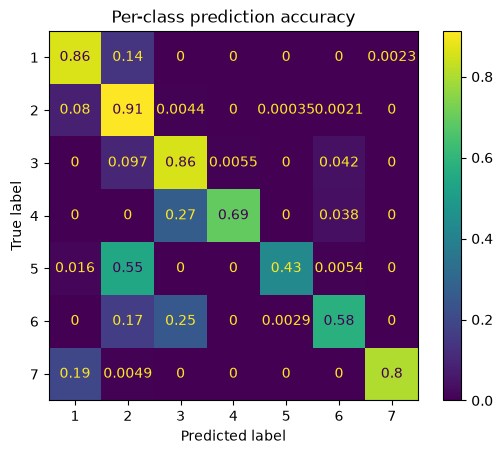

In [7]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize='true')   # normalize so each row sums to 1
plt.title('Per-class prediction accuracy')

The following is another way of interpreting the same information. Let's look at the error percentage for each class. That is, how frequently is our model incorrect about our tree cover classes?

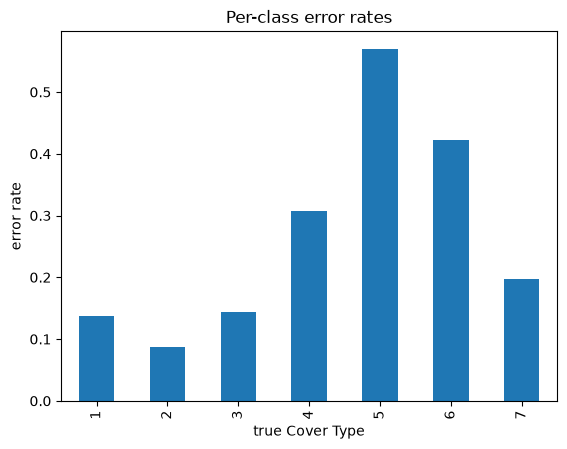

In [8]:
# error rate per class
wrong = pd.Series(y_pred != y_test.values, index=y_test.index)
wrong.groupby(y_test).mean().plot.bar()
plt.xlabel('true Cover Type')
plt.ylabel('error rate')
plt.title('Per-class error rates');

**Q:** Which classes have the highest error rates, and which classes are they confused with? How does this relate to class size?

**A:** Class 5 had the highest error rate, and Class 5 was most confused with Class 2. This is due to how a majority of the data that was sources is Class 2

## 4. Hyperparameter optimization: number of trees

A **hyperparameter** is a setting we choose *before* training, like `n_estimators`. To choose it fairly, we hold out part of the training data as a **validation set**, so the test set stays untouched until the very end.

Note: The validation set is **different** from the test set!

In [9]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42) # notice we are splitting within TRAIN set only.

**Question:** Please complete the code cell below to loop over the numbers of trees in `n_trees_list`: for each `n`, create a forest with `n` trees (`random_state=42`, `n_jobs=-1`), fit it on `X_tr, y_tr`, and append its accuracy on `X_val, y_val` to `val_acc`.

In [10]:
n_trees_list = [1, 5, 10, 25, 50, 100, 200]
# we'll store validation accuracy scores for each n_trees value below.
val_acc = [] 

for n in n_trees_list:
    model = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)   # n trees on this pass
    model.fit(X_tr, y_tr)                                                           # fit on the smaller TRAIN split
    val_acc.append(model.score(X_val, y_val))                                        # accuracy on the VALIDATION set

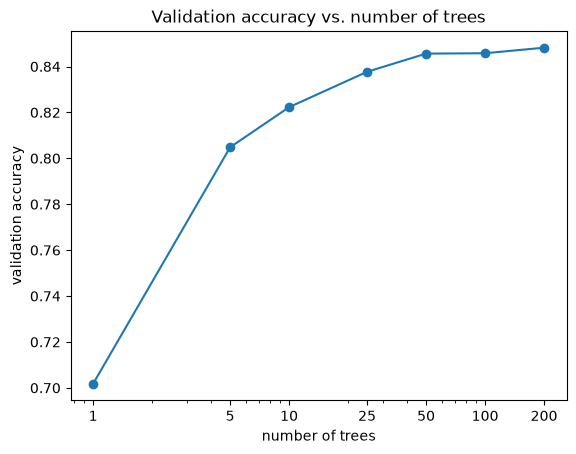

In [11]:
plt.plot(n_trees_list, val_acc, marker='o')
plt.xscale('log')
plt.xticks(n_trees_list, n_trees_list)
plt.xlabel('number of trees')
plt.ylabel('validation accuracy')
plt.title('Validation accuracy vs. number of trees');

**Qcuestion:** Retrain a forest with the best number of trees (`best_n`) on the **full** training set (`X_train, y_train`), then compare its test accuracy to the 100-tree forest `rf`.

NOTE: Use `np.argmax()` to get the index of the best-performing n_trees parameter from the `val_acc` array. HINT: a great way to learn about functions is to go to the package documentation website.

In [12]:
best_tree_index = int(np.argmax(val_acc))
best_n = n_trees_list[best_tree_index]
print('Best number of trees:', best_n)

rf_best = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
rf_best.fit(X_train, y_train)                                  # the FULL training set

print(f'Test accuracy: {rf.score(X_test, y_test):.3f} (100 trees) vs {rf_best.score(X_test, y_test):.3f} ({best_n} trees)')

Best number of trees: 200
Test accuracy: 0.868 (100 trees) vs 0.872 (200 trees)


**Q:** How does validation accuracy change as the number of trees increases? Where do the returns diminish, and what is the cost of adding more trees?

**A:** As the number of trees increases, the test accuracy increases as well. The returns deminish as it takes more time and computing power to have a negligible increase in accuracy. 

*We will keep using the 100-tree forest `rf` for the rest of the lab.*

## 5. Handling class imbalance
Overall accuracy hides poor accuracy on rare types. **Undersampling** caps the number of training rows per class so the big classes don't dominate (we resample the training set only; the test set stays untouched).

In [13]:
cap = 1000   # This keeps at MOST 1000 training rows per class
train = X_train.assign(Cover_Type=y_train)
balanced = train.groupby('Cover_Type').head(cap)
X_bal, y_bal = balanced.drop(columns='Cover_Type'), balanced['Cover_Type']
print(y_bal.value_counts().sort_index())

Cover_Type
1    1000
2    1000
3    1000
4     207
5     746
6    1000
7    1000
Name: count, dtype: int64


**Question:** Please complete the code cell below to create a second forest `rf_bal` (same settings as before) and fit it on the undersampled data `X_bal, y_bal`, then use it to predict on `X_test`. The rest of the cell compares it to the original.

Overall accuracy: original 0.868, undersampled 0.662


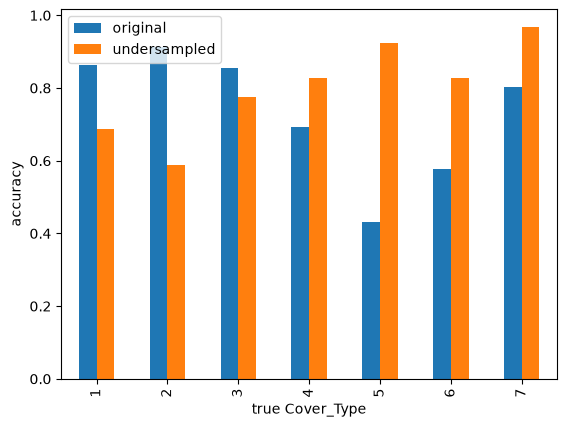

In [14]:
rf_bal = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_bal.fit(X_bal, y_bal)                                  # the undersampled training data

y_pred_bal = rf_bal.predict(X_test)                        # predict on the (untouched) test set
print(f'Overall accuracy: original {(y_pred == y_test).mean():.3f}, undersampled {(y_pred_bal == y_test).mean():.3f}')

# per-class accuracy, before vs after. Don't touch anything below!!
acc = lambda p: pd.Series(p == y_test.values, index=y_test.index).groupby(y_test).mean()
pd.DataFrame({'original': acc(y_pred), 'undersampled': acc(y_pred_bal)}).plot.bar()
plt.xlabel('true Cover_Type'); plt.ylabel('accuracy');

**Q:** How did undersampling change accuracy for the rare classes? What happened to overall accuracy, and why do you think that is?

**A:** Undersampling increased the accuracy for the rare classes but generally decreases the overall accuracy. This is possibly due to the reduced bias towards the more common classes.

## 6. Feature importance

We can use the `feature_importances_` method of our random forest model `rf` to assess how important our inputs are quantitatively.

Text(0.5, 0, 'importance')

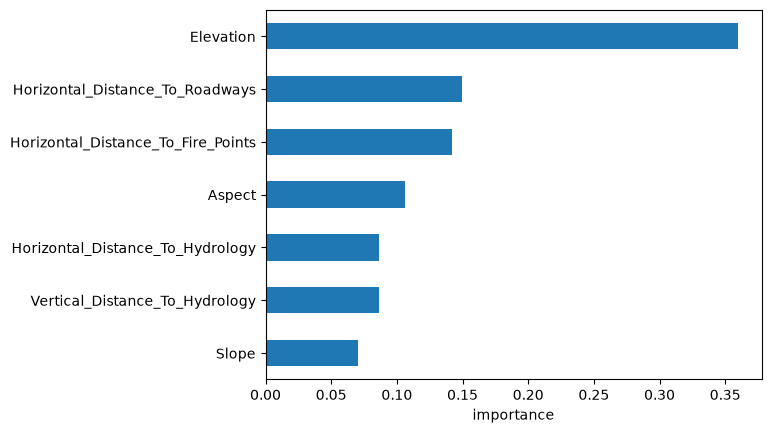

In [15]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh()
plt.xlabel('importance')

Let's see how well our model does when we **exclude the lowest 3 input features** by importance. 

**Question:** Please complete the code cell below to find the names of the 3 least important features (`imp` is sorted from least to most important), fit a new forest `rf_small` (same settings) on `X_train` without those columns, and compute its test accuracy `acc_small` on `X_test` without those columns.

In [16]:
# `imp` is sorted from least to most important
least = imp.index[:3] # slice off the 3 least important feature names (which are the FIRST 3 elements of this array)
print('Dropping:', list(least),'\n')

rf_small = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_small.fit(X_train.drop(columns=least), y_train)          # training data without those columns
acc_small = rf_small.score(X_test.drop(columns=least), y_test)   # test accuracy without those columns

print(f'All-feature accuracy: {rf.score(X_test, y_test):.3f} \nWithout {list(least)}: {acc_small:.3f}')

Dropping: ['Slope', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Hydrology'] 

All-feature accuracy: 0.868 
Without ['Slope', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Hydrology']: 0.846


**Q:** Which feature is most important? How did accuracy change when you dropped the 3 least important features?

**A:** The most important feature to class is elevation. When dropping the least important features, the accuracy decreased. 

## Mini-Evals (please fill out!!!)

1. Please rate 1-5 how this lab was for you. 1 := this was too difficult, 5 := I could do this in my sleep.

*Answer*:4

2. What is something you wished I covered in this lab? 

*Answer*:n/a

# Lab submission

Please `Restart` and `Run All` on this notebook and submit this lab when you are done!